# 06 · Etapa 5: personas y vehículos
Las etapas 1-4 dejan a las personas dentro de `equipo_bajo`, `mezcla_no_identificada` o `compacto_plausible`, y a la camioneta dentro de `viga_o_tuberia`. Esta etapa parte de las clases de la etapa 4 (`entregable/etapa4_clases.npz`) y busca **objetos libres sobre el piso**:

1. Altura sobre el **piso local** (mediana z del piso por celda de 1 m), porque el piso no es perfectamente plano.
2. Candidatos: todo lo que no es piso, techo ni columna, entre 0.05 y 2.6 m sobre el piso.
3. **DBSCAN** en xyz (eps 0.15 m) forma objetos. Un objeto que toca el corte de 2.6 m está unido a estructura más alta y se descarta.
4. **Vehículo**: huella PCA de 3-7 m × ≥1 m, altura 1.2-2.6 m, menos de 30 % de puntos bajo 0.45 m (descarta tarimas y plataformas). Absorbe fragmentos vecinos dentro de su caja.
5. **Persona**: altura 1.45-1.95 m y huella de 0.4-1.0 m.
6. **Grupos de personas pegadas**: se buscan cabezas (cimas locales a altura humana, DBSCAN xy) con cuerpo debajo, nada encima y poco alrededor a la misma altura; cada cabeza toma los puntos a menos de 0.38 m en xy.

El escáner FARO gira mientras la gente camina, así que una persona en movimiento aparece como **rebanadas delgadas** (ancho ≈ 2 cm) con silueta humana. Se cuentan como detecciones de persona, no como personas distintas.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if Path('src/pcseg').exists() else Path.cwd().parents[1]
sys.path.insert(0, str(ROOT/'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image
from pcseg.io import read_ply, write_ply
from pcseg.stages import detect_people_vehicles
plt.switch_backend('Agg')
ENT = ROOT/'entregable'; FIG = ROOT/'doc/figs'
CLASS_COLORS = {'piso':(70,155,70),'techo':(90,140,230),'columna':(230,60,55),
 'viga_horizontal':(245,170,35),'viga_o_tuberia':(225,125,25),'equipo_bajo':(155,75,190),
 'compacto_plausible':(30,200,190),'mezcla_no_identificada':(210,110,160),'ruido':(45,45,45),
 'persona':(255,0,255),'vehiculo':(20,20,140)}
cloud = read_ply(ROOT/'data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
stage4 = np.load(ENT/'etapa4_clases.npz')
before = stage4['nombres'][stage4['codigos']]
assert len(before) == len(cloud['xyz']) == 1647021

In [2]:
after, obj, objects = detect_people_vehicles(cloud['xyz'], before)
objects.to_csv(ENT/'final_personas_vehiculos.csv', index=False)
display(objects.round(2))
moved = pd.crosstab(pd.Series(before[after != before], name='antes'), pd.Series(after[after != before], name='ahora'))
display(moved)

,id,clase,n_puntos,altura,largo,ancho,cx,cy,origen
0,0,vehiculo,6586,1.79,6.00,2.37,22.54,13.06,regla_vehiculo
1,1,persona,569,1.76,0.63,0.36,17.90,14.53,regla_persona
2,2,persona,423,1.72,0.89,0.14,5.90,-3.11,regla_persona
3,3,persona,1005,1.66,0.77,0.54,2.89,-4.73,regla_persona
4,4,persona,457,1.74,0.70,0.23,3.91,-7.92,regla_persona
5,5,persona,110,1.72,0.43,0.03,0.26,-4.21,regla_persona
6,6,persona,160,1.73,0.40,0.05,5.89,-4.56,regla_persona
7,7,persona,675,1.73,0.88,0.52,16.16,18.85,regla_persona
8,8,persona,173,1.70,0.55,0.01,17.86,-1.55,regla_persona
9,9,persona,136,1.65,0.59,0.01,19.14,6.68,regla_persona


ahora,persona,vehiculo
antes,,
compacto_plausible,636,0
equipo_bajo,5082,0
mezcla_no_identificada,1249,0
ruido,368,58
viga_horizontal,1282,1533
viga_o_tuberia,1510,4995


In [3]:
colors = np.array([CLASS_COLORS[c] for c in after], np.uint8)
write_ply(ENT/'final_segmentos.ply', cloud['xyz'], colors, cloud['normals'])
restored = read_ply(ENT/'final_segmentos.ply')
assert np.array_equal(restored['rgb'], colors) and np.array_equal(restored['xyz'], cloud['xyz'])
names = sorted(set(after))
pd.DataFrame([dict(clase_heuristica=n, R=CLASS_COLORS[n][0], G=CLASS_COLORS[n][1], B=CLASS_COLORS[n][2]) for n in names]).to_csv(ENT/'final_leyenda.csv', index=False)
seg4 = pd.read_csv(ENT/'final_segmentos.csv').groupby('clase_heuristica').size()
totals = pd.DataFrame(dict(n_puntos=pd.Series(after).value_counts()))
totals['porcentaje'] = 100*totals.n_puntos/len(after)
totals['n_segmentos'] = [int((objects.clase == n).sum()) if n in ('persona','vehiculo') else int(seg4.get(n, 0)) for n in totals.index]
totals.index.name = 'clase_heuristica'
totals.reset_index().to_csv(ENT/'final_clases.csv', index=False)
display(totals.round(2))

,n_puntos,porcentaje,n_segmentos
clase_heuristica,,,
piso,488252,29.64,1
viga_horizontal,316359,19.21,53
viga_o_tuberia,302955,18.39,76
mezcla_no_identificada,254835,15.47,63
columna,113352,6.88,17
techo,111522,6.77,1
equipo_bajo,28778,1.75,22
persona,10127,0.61,28
ruido,8689,0.53,1


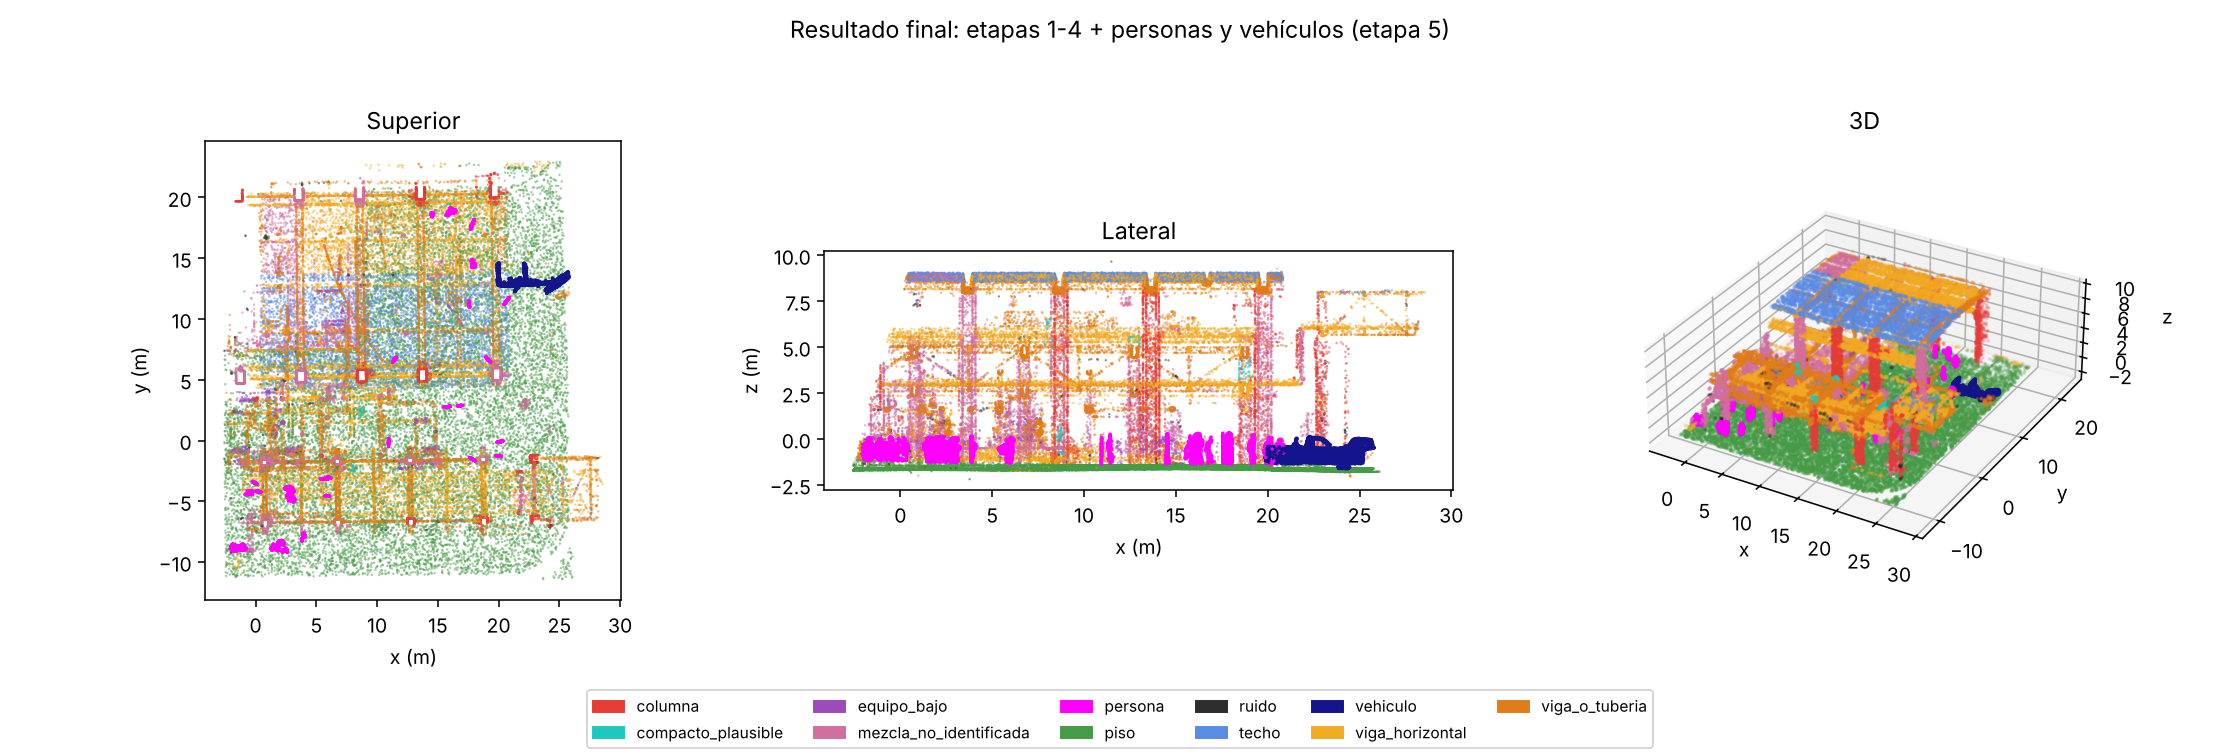

In [4]:
xyz = cloud['xyz']; rng = np.random.default_rng(0)
take = rng.choice(len(xyz), 60000, replace=False)
special = np.flatnonzero(np.isin(after, ['persona','vehiculo']))
take = np.unique(np.r_[take, special])
p = xyz[take]; c = colors[take]/255.; big = np.isin(after[take], ['persona','vehiculo'])
fig = plt.figure(figsize=(16,5.4))
for i, j in enumerate((1, 2)):
    ax = fig.add_subplot(1, 3, i+1)
    ax.scatter(p[~big,0], p[~big,j], c=c[~big], s=1.5, alpha=.5, linewidths=0)
    ax.scatter(p[big,0], p[big,j], c=c[big], s=3, linewidths=0)
    ax.set(xlabel='x (m)', ylabel='y (m)' if j == 1 else 'z (m)', aspect='equal', title='Superior' if j == 1 else 'Lateral')
ax = fig.add_subplot(1, 3, 3, projection='3d'); ax.scatter(*p.T, c=c, s=1, alpha=.6)
ax.set(xlabel='x', ylabel='y', zlabel='z', title='3D'); ax.set_box_aspect(np.ptp(p, axis=0))
fig.legend(handles=[Patch(color=np.array(CLASS_COLORS[n])/255, label=n) for n in names], loc='lower center', ncol=6, fontsize=8)
fig.suptitle('Resultado final: etapas 1-4 + personas y vehículos (etapa 5)')
fig.tight_layout(rect=(0, .1, 1, .94)); fig.savefig(FIG/'exp_06_final.png', dpi=140); plt.close(fig)
display(Image(filename=str(FIG/'exp_06_final.png')))

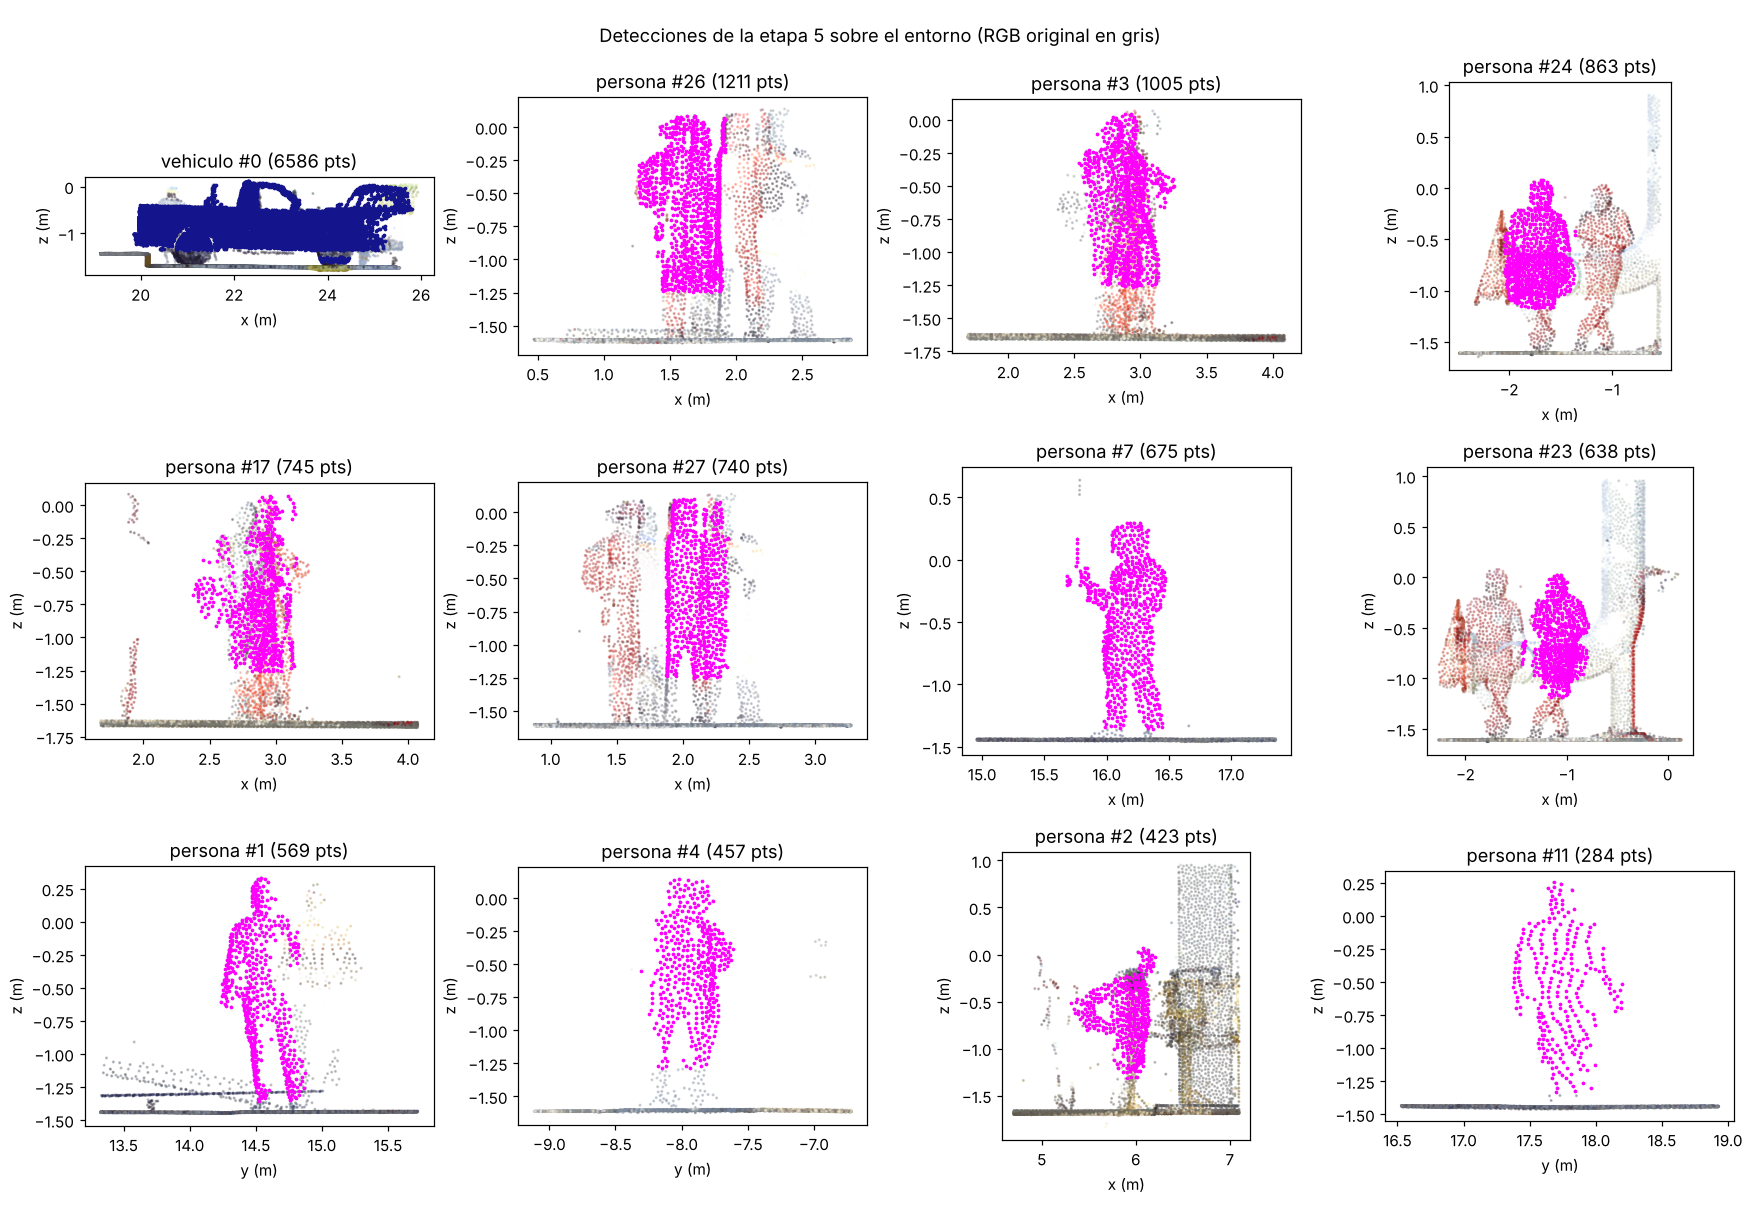

In [5]:
# Galería: cada detección (magenta/azul) sobre su entorno con el RGB original.
rgb = cloud['rgb']/255.
show = [int(objects.loc[objects.clase=='vehiculo','id'].iloc[0])] + objects.loc[objects.clase=='persona'].sort_values('n_puntos', ascending=False).id.head(11).tolist()
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, k in zip(axes.flat, show):
    ids = np.flatnonzero(obj == k); q = xyz[ids]; m0 = q.mean(axis=0); r = 3.4 if after[ids[0]] == 'vehiculo' else 1.2
    j = 1 if np.ptp(q[:,0]) < np.ptp(q[:,1]) else 0
    near = (np.abs(xyz[:,0]-m0[0]) < r) & (np.abs(xyz[:,1]-m0[1]) < r) & (np.abs(xyz[:,2]-m0[2]) < 1.6)
    ax.scatter(xyz[near,j], xyz[near,2], c=rgb[near], s=1, alpha=.35)
    ax.scatter(q[:,j], q[:,2], c=[colors[ids[0]]/255.], s=2)
    ax.set(aspect='equal', xlabel='xy'[j]+' (m)', ylabel='z (m)', title=f"{after[ids[0]]} #{k} ({len(ids)} pts)")
fig.suptitle('Detecciones de la etapa 5 sobre el entorno (RGB original en gris)')
fig.tight_layout(); fig.savefig(FIG/'exp_06_personas_vehiculos.png', dpi=110); plt.close(fig)
display(Image(filename=str(FIG/'exp_06_personas_vehiculos.png')))

In [6]:
# La clase previa del PLY de clase también se reescribe con propiedades red/green/blue estándar.
base = read_ply(ENT/'clase_segmentos.ply')
write_ply(ENT/'clase_segmentos.ply', base['xyz'], base['rgb'], base['normals'])
print(open(ENT/'final_segmentos.ply', 'rb').read(260).split(b'end_header')[0].decode())

ply
format binary_little_endian 1.0
element vertex 1647021
property float x
property float y
property float z
property uchar red
property uchar green
property uchar blue
property float nx
property float ny
property float nz



**Lectura.** La camioneta (antes `viga_o_tuberia`) queda como un solo objeto. Las personas salen de `equipo_bajo`, `mezcla_no_identificada`, `compacto_plausible` y `viga_*`. Las detecciones por rebanadas no son un conteo de personas: una misma persona caminando puede dar varias. Límites conocidos: personas pegadas a estructura que pasa de 2.6 m o tapadas hasta la cintura (detrás de una mesa) no se detectan; un objeto delgado de 1.5-1.9 m con silueta parecida podría pasar como persona.